# 04 · Segmentación dinámica: ABC móvil, fase de ciclo de vida y servicio diferenciado

Continuación de `03_inventario.ipynb`. Ahí el servicio diferenciado por ABC (A 95 / B 90 / C 80) costó 7–18 % más
stock que un nivel uniforme con el mismo fill rate. Pero ese ABC era **estático**: se calculó una sola vez con los
12 meses a ago-2025 y no reconocía a los SKUs nuevos (`sin_ABC`). Aquí se repite la prueba con una segmentación que
se recalcula **en cada origen**, solo con datos ≤ origen. Código en `src/segmentacion.py`; decisiones en
LOG_DECISIONES #31.

| Etiqueta | Definición (en cada mes t, datos ≤ t) |
|---|---|
| **ABC móvil** | Valor = Σ unidades × precio MXN del mes, ventana de 12 meses. A/B/C hasta 80/95/100 % del valor acumulado. Sin venta en 12 meses → C |
| Anualización (< 12 meses de vida) | Edad 1–11: (valor 12 m − valor del mes 0) × 12 / edad, **sin el mes de lanzamiento** (llenado de canal). Edad 0: valor del mes 0 × 12 / factor de lanzamiento |
| **Fase de ciclo de vida** | `introducción`: edad < 12 meses. `dormido`: sin venta en los últimos 12 meses (repuesto que se conserva y puede volver a venderse). Sin venta en 6 meses pero sí en 12 → `declive`. Si no, r = media de los últimos 6 meses ÷ media de los mismos 6 meses del año anterior (quita la estacionalidad, sin el mes 0): `crecimiento` r ≥ 1.3 · `madurez` · `declive` r ≤ 1/1.3 |
| Nivel de servicio por SKU-mes | El SS empírico de cada decisión T usa el nivel α de la etiqueta en T. Los ajustes por fase mueven α por la escalera 0 (sin SS) · 70 · 80 · 90 · 95 · 98 % |

Las métricas son las mismas de `03_inventario` (SS empírico, venta perdida), calculadas con `ML_base` para los
maduros. La política elegida usa `TD_estado` (LOG #45), pero en inventario los dos empatan (±1–7 %) y aquí todas las
comparaciones son relativas, **a igual fill rate** contra la curva uniforme del mismo modelo.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from estilo import aplicar, COLORES, AZUL, GRIS, GRIS_CLARO
import segmentacion as sg
import features as ft

aplicar()
pd.set_option("display.width", 220, "display.max_columns", 40)
PROC = RAIZ / "data" / "processed"
RES = PROC / "resultados"
FIG = RAIZ / "reports" / "figuras"
seg = pd.read_parquet(PROC / "segmentacion_sku_mes.parquet")
r = pd.read_csv(RES / "inv_segmentacion.csv")
rs = pd.read_csv(RES / "inv_segmentacion_seg.csv")
datos = ft.Datos.cargar()
print(f"Factor de lanzamiento (Σ mes 0 ÷ Σ media de meses 1–11, lanzamientos ≤ ago-2024): {sg.factor_lanzamiento(datos):.2f}")

Factor de lanzamiento (Σ mes 0 ÷ Σ media de meses 1–11, lanzamientos ≤ ago-2024): 1.15


## 1. ABC móvil

### 1.1 Contra el ABC estático (ago-2025)

En ago-2025 los dos usan la misma ventana, así que solo deberían diferir por la anualización y por los SKUs nuevos.

In [2]:
st = pd.read_parquet(PROC / "clasificacion_sku.parquet").set_index("id_articulo").abc.astype(str)
a = seg[seg.mes == "2025-08-01"].set_index("id_articulo")
print("Filas = ABC estático · columnas = ABC móvil (ago-2025)")
print(pd.crosstab(st.reindex(a.index).fillna("sin_ABC"), a.abc_movil, margins=True, margins_name="total").to_string())

Filas = ABC estático · columnas = ABC móvil (ago-2025)
abc_movil    A    B     C  total
abc                             
A          207    0     1    208
B            8  203     1    212
C            1   13   436    450
sin_ABC      0    0  1469   1469
total      216  216  1907   2339


### 1.2 Efecto de anualizar a los SKUs jóvenes

SKU-mes con menos de 12 meses de vida, desde sep-2024. Sin anualizar, un SKU joven compite con un año completo de
venta de los demás y casi siempre cae en C.

In [3]:
j = seg[(seg.edad < 12) & (seg.mes >= "2024-09-01")]
print("Filas = sin anualizar · columnas = anualizado")
print(pd.crosstab(j.abc_sin_anualizar, j.abc_movil, margins=True, margins_name="total").to_string())

Filas = sin anualizar · columnas = anualizado
abc_movil            A    B     C  total
abc_sin_anualizar                       
A                  130    7     5    142
B                   95  314    37    446
C                   42  247  1494   1783
total              267  568  1536   2371


### 1.3 Estabilidad: transición de un mes al siguiente (desde sep-2024)

In [4]:
s = seg.sort_values(["id_articulo", "mes"]).copy()
s["abc_prev"] = s.groupby("id_articulo").abc_movil.shift()
s["fase_prev"] = s.groupby("id_articulo").fase.shift()
x = s[(s.mes >= "2024-09-01") & s.abc_prev.notna()]
print(f"SKU-mes que cambian de clase ABC: {(x.abc_movil != x.abc_prev).mean():.1%}")
print(pd.crosstab(x.abc_prev, x.abc_movil, normalize="index").round(3).to_string())

SKU-mes que cambian de clase ABC: 1.5%


abc_movil      A      B      C
abc_prev                      
A          0.962  0.036  0.002
B          0.037  0.923  0.040
C          0.000  0.005  0.995


## 2. Fase de ciclo de vida

### 2.1 Distribución y cruce con el ABC (SKU-mes desde sep-2024)

In [5]:
x = seg[seg.mes >= "2024-09-01"]
print(pd.crosstab(x.abc_movil, x.fase, margins=True, margins_name="total")[sg.FASES + ["total"]].to_string())
print()
v = x.pivot_table(index="abc_movil", columns="fase", values="valor_anual", aggfunc="sum")
print("% del valor anual por celda")
print((v / v.sum().sum() * 100).round(1)[sg.FASES].to_string())

fase       introducción  crecimiento  madurez  declive  dormido  total
abc_movil                                                             
A                   267         1390     2252     1509        0   5418
B                   568         1405     1475     1955        0   5403
C                  1536         2881     1515     5258    36410  47600
total              2371         5676     5242     8722    36410  58421

% del valor anual por celda
fase       introducción  crecimiento  madurez  declive  dormido
abc_movil                                                      
A                   2.4         16.8     41.0     19.7      NaN
B                   1.5          3.8      4.2      5.5      NaN
C                   0.6          1.3      1.0      2.0      0.0


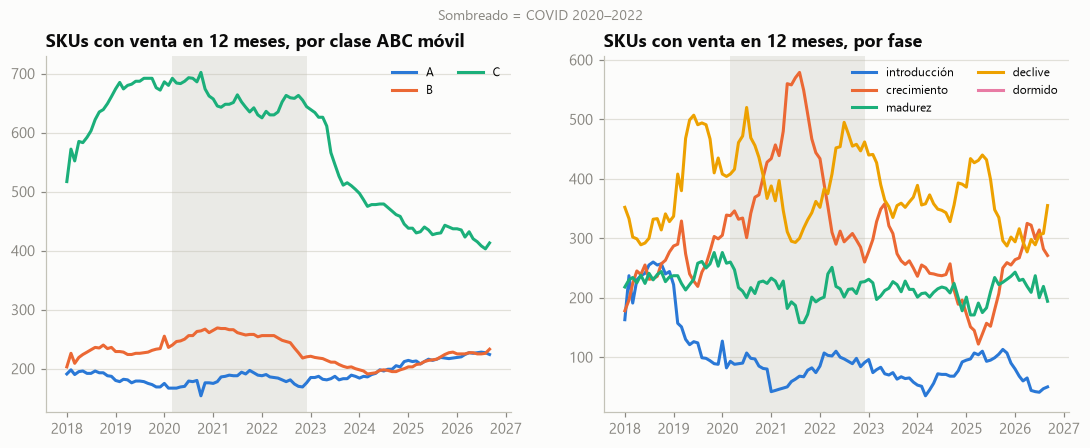

In [6]:
t = seg[(seg.mes >= "2018-01-01") & (seg.valor_anual > 0)]     # solo SKUs con venta en los últimos 12 meses
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for i, c in enumerate(["A", "B", "C"]):
    n = t[t.abc_movil == c].groupby("mes").size()
    ax[0].plot(n.index, n.values, lw=2, color=COLORES[i], label=c)
for i, f in enumerate(sg.FASES):
    n = t[t.fase == f].groupby("mes").size()
    ax[1].plot(n.index, n.values, lw=2, color=COLORES[i], label=f)
ax[0].set_title("SKUs con venta en 12 meses, por clase ABC móvil")
ax[1].set_title("SKUs con venta en 12 meses, por fase")
for a in ax:
    a.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2022-12-01"), color=GRIS_CLARO, alpha=.3, lw=0)
    a.legend(fontsize=8, ncol=2)
fig.suptitle("Sombreado = COVID 2020–2022", fontsize=9, color=GRIS)
fig.savefig(FIG / "23_segmentacion_movil.png"); plt.show()

### 2.2 Estabilidad de la fase (SKUs no dormidos)

In [7]:
x = s[(s.mes >= "2024-09-01") & s.fase_prev.notna() & (s.fase != "dormido") & (s.fase_prev != "dormido")]
print(f"SKU-mes que cambian de fase: {(x.fase != x.fase_prev).mean():.1%}")
print(pd.crosstab(x.fase_prev, x.fase, normalize="index").round(2).to_string())

SKU-mes que cambian de fase: 19.7%
fase          crecimiento  declive  introducción  madurez
fase_prev                                                
crecimiento          0.80     0.06          0.00     0.14
declive              0.02     0.86          0.00     0.11
introducción         0.03     0.03          0.92     0.01
madurez              0.15     0.19          0.00     0.66


### 2.3 ¿El pronóstico se equivoca distinto por fase?

Error de `ML_base` (SKUs maduros) y de `Media_post` (jóvenes) a h = 3, con la fase en el **origen** del pronóstico.
Sesgo = Σ(pronóstico − real) / Σ real.

In [8]:
pr = pd.concat([pd.read_parquet(RES / f"pronosticos_{p}.parquet").assign(periodo=p)[["id_articulo", "origen", "y", "ML_base", "periodo"]]
                .rename(columns={"ML_base": "f"}) for p in ("validacion", "prueba")] +
               [pd.read_parquet(RES / f"cold_jovenes_{p}.parquet").assign(periodo=p)[["id_articulo", "origen", "y", "Media_post", "periodo"]]
                .rename(columns={"Media_post": "f"}) for p in ("validacion", "prueba")])
pr = pr.merge(seg[["id_articulo", "mes", "fase"]].rename(columns={"mes": "origen"}), on=["id_articulo", "origen"], how="left")
g = pr.assign(e=pr.f - pr.y, ae=(pr.f - pr.y).abs()).groupby(["periodo", "fase"])
t = pd.DataFrame({"sku_mes": g.size(), "sesgo": g.e.sum() / g.y.sum(), "WAPE": g.ae.sum() / g.y.sum(),
                  "% unidades": g.y.sum() / pr.groupby("periodo").y.sum()}).round(3)
print(t.unstack(0).reindex(sg.FASES).to_string())

             sku_mes             sesgo              WAPE            % unidades           
periodo       prueba validacion prueba validacion prueba validacion     prueba validacion
fase                                                                                     
introducción  1195.0     1122.0 -0.196     -0.119  0.816      0.948      0.019      0.015
crecimiento   3224.0     2519.0  0.058      0.323  0.595      0.731      0.216      0.125
madurez       2910.0     2412.0  0.080      0.219  0.422      0.404      0.577      0.561
declive       4167.0     4485.0 -0.130      0.090  0.577      0.482      0.189      0.299
dormido          NaN        NaN    NaN        NaN    NaN        NaN        NaN        NaN


## 3. Servicio diferenciado: resultados

Cada política se compara con el **stock que necesitaría el nivel uniforme para lograr el mismo fill rate**
(interpolación log-lineal sobre la curva uniforme 70–98 %). Negativo = la política ahorra stock.

In [9]:
filas = []
for per, g in r.groupby("periodo"):
    u = g[g.politica.str.fullmatch(r"Uniforme \d+%")].sort_values("fill_rate")
    for _, x in g.iterrows():
        eq = np.exp(np.interp(x.fill_rate, u.fill_rate, np.log(u.stock_prom_mxn)))
        filas.append({"politica": x.politica, "periodo": per, "fill": x.fill_rate, "stock_M": x.stock_prom_mxn / 1e6,
                      "uniforme_mismo_fill_M": eq / 1e6, "vs_uniforme": x.stock_prom_mxn / eq - 1,
                      "riesgo_M": x.stock_riesgo_mxn / 1e6})
comp = pd.DataFrame(filas)
orden = list(dict.fromkeys(r.politica))
tab = comp.pivot(index="politica", columns="periodo", values=["fill", "stock_M", "vs_uniforme"]).reindex(orden)
fmt = tab.copy()
for c in fmt.columns:
    fmt[c] = tab[c].map(lambda v: f"{v:+.0%}" if c[0] == "vs_uniforme" else (f"{v:.3f}" if c[0] == "fill" else f"{v:.1f}"))
print(fmt.to_string())
print()
print("Stock en riesgo de obsolescencia al cierre de sep-2026 (M MXN):")
print(comp[comp.periodo == "prueba"].set_index("politica").riesgo_M.reindex(orden).round(2).to_string())

                                      fill            stock_M            vs_uniforme           
periodo                             prueba validacion  prueba validacion      prueba validacion
politica                                                                                       
Uniforme 70%                         0.830      0.882    21.9       29.7         +0%        -0%
Uniforme 80%                         0.873      0.884    30.2       31.9         -0%        +0%
Uniforme 90%                         0.924      0.935    52.4       44.9         -0%        +0%
Uniforme 95%                         0.954      0.970    85.0       72.1         +0%        +0%
Uniforme 98%                         0.981      0.988   161.7      141.3         +0%        -0%
ABC estático 95/90/80                0.931      0.956    69.7       63.0        +19%        +6%
ABC móvil 95/90/80                   0.933      0.950    74.0       64.7        +22%       +19%
ABC móvil + fase                     0.9

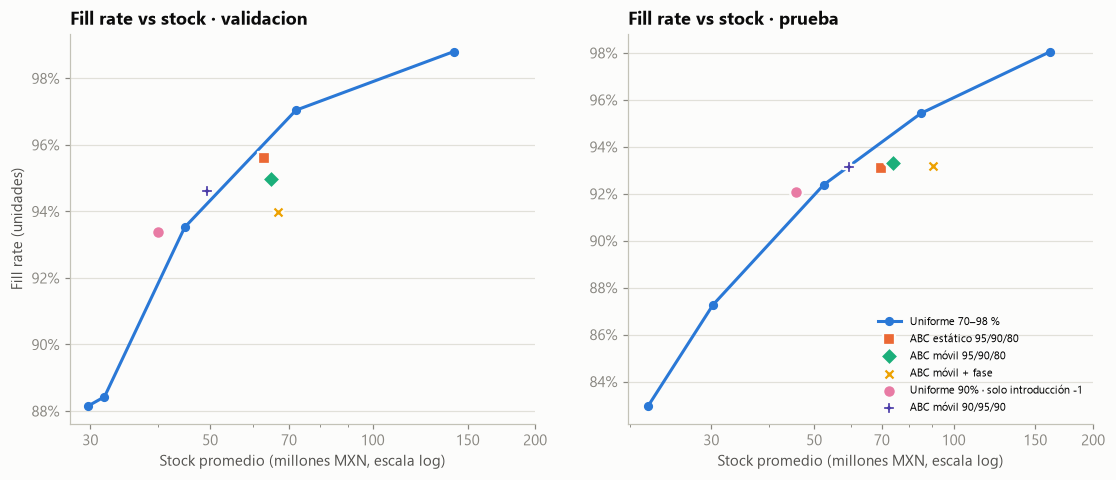

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
marcas = {"ABC estático 95/90/80": ("s", COLORES[1]), "ABC móvil 95/90/80": ("D", COLORES[2]),
          "ABC móvil + fase": ("X", COLORES[3]), "Uniforme 90% · solo introducción -1": ("o", COLORES[4]),
          "ABC móvil 90/95/90": ("P", COLORES[6])}
for a, per in zip(ax, ["validacion", "prueba"]):
    g = r[r.periodo == per]
    u = g[g.politica.str.fullmatch(r"Uniforme \d+%")].sort_values("fill_rate")
    a.plot(u.stock_prom_mxn / 1e6, u.fill_rate, lw=2, marker="o", ms=5, color=AZUL, label="Uniforme 70–98 %")
    for p, (m, c) in marcas.items():
        x = g[g.politica == p].iloc[0]
        a.scatter(x.stock_prom_mxn / 1e6, x.fill_rate, marker=m, s=70, color=c, edgecolor="#fcfcfb", lw=1.5, zorder=3, label=p)
    a.set_xscale("log")
    a.set_xticks([30, 50, 70, 100, 150, 200])
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    a.xaxis.set_minor_formatter(plt.NullFormatter())
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    a.set_xlabel("Stock promedio (millones MXN, escala log)")
    a.set_title(f"Fill rate vs stock · {per}")
ax[0].set_ylabel("Fill rate (unidades)")
ax[1].legend(fontsize=7.5, loc="lower right")
fig.savefig(FIG / "24_servicio_diferenciado.png"); plt.show()

### 3.1 Por segmento (prueba)

Las métricas por segmento usan la etiqueta vigente en la decisión anterior a cada mes de demanda.

In [11]:
pols = ["Uniforme 90%", "Uniforme 90% · solo introducción -1", "Uniforme 90% + fase", "ABC móvil 95/90/80"]
x = rs[(rs.periodo == "prueba") & rs.politica.isin(pols)].copy()
x["stock_M"] = x.stock_prom_mxn / 1e6
t = x.pivot_table(index=["dimension", "segmento"], columns="politica", values=["fill_rate", "cobertura_meses", "stock_M"])
print(t.reindex(columns=pols, level=1).round(2).to_string())

                       cobertura_meses                                                                               fill_rate                                                                                 stock_M                                                                           
politica                  Uniforme 90% Uniforme 90% · solo introducción -1 Uniforme 90% + fase ABC móvil 95/90/80 Uniforme 90% Uniforme 90% · solo introducción -1 Uniforme 90% + fase ABC móvil 95/90/80 Uniforme 90% Uniforme 90% · solo introducción -1 Uniforme 90% + fase ABC móvil 95/90/80
dimension segmento                                                                                                                                                                                                                                                                               
abc_movil A                       2.98                                2.76                3.29               4.79         0.94    

## 4. Hallazgos

1. **El ABC móvil es estable y corrige dos fallas del estático.** Solo el 1.5 % de los SKU-mes cambia de clase de un
   mes al siguiente. En ago-2025 coincide con el estático en los SKUs maduros (8 B → A y 13 C → B por la
   anualización), pero además clasifica a los 1,469 SKUs `sin_ABC`. El estático tenía **leakage en validación**:
   se calculó con datos hasta ago-2025, después del final de la validación (jun-2025). Por eso su +6 % en validación
   era optimista; el ABC móvil, que es causal, da +19 %.
2. **Anualizar sí importa para los jóvenes.** Sin anualizar, la mayoría de los SKU-mes jóvenes cae en C. Anualizados,
   unos 250 pasan de C a B y unos 95 de B a A. El factor de lanzamiento medido como razón de sumas es **1.15**, no
   4×. El "4×" del análisis de cold start describía al SKU típico; en los SKUs grandes, que dominan el valor, el mes
   de lanzamiento pesa poco más que un mes normal.
3. **Aun con el ABC móvil, el servicio 95/90/80 no conviene:** cuesta **+19 % (validación) y +22 % (prueba)** más
   stock que el nivel uniforme con el mismo fill rate. La razón es la misma de antes. Con el nivel uniforme al 90 %,
   los SKUs A ya logran ~94 % de fill con 3.0 meses de cobertura, y subirlos a 95 % es lo más caro: ~21 M MXN por
   2 puntos. Bajar C a 80 % ahorra muy poco (~1 M MXN), porque su stock es de cola larga, no de SS.
4. **La fase de ciclo de vida, tal como está definida, es ruidosa:** el 20 % de los SKU-mes activos cambia de fase de
   un mes al siguiente (madurez solo se mantiene el 66 %). La figura 23 muestra además que las fases se mueven en
   **olas de todo el mercado** (crecimiento en 2021 por el COVID, declive en caida_2019 y caida_2024): la
   tendencia de 6 meses mide más el ciclo agregado que el ciclo de vida de cada SKU. Eso es caro en una política order-up-to porque **el
   inventario sube rápido y baja lento**: cuando el nivel α sube, el pedido es inmediato, y cuando baja, el exceso
   solo se drena con la venta. Por eso combinar fases con ABC (`ABC móvil + fase`) cuesta **+40 % / +52 %**, y el
   paquete completo de fases sobre el uniforme 90 % cuesta +7 % / +13 % (validación / prueba).
5. **Descomposición de los ajustes por fase (sobre el uniforme 90 %):**
   - **Introducción −1 (90 → 80 % en SKUs con < 12 meses): ahorra 10 % en validación y 10 % en prueba** a igual
     fill, y baja el stock en riesgo de 2.59 a 2.13 M MXN. Es el único ajuste que mejora en los dos periodos. Ataca
     el sobre-stock de los nuevos que vimos en `03_inventario` (~20 meses de cobertura): el SS de la clase "joven"
     compensaba de más el sesgo de `Media_post`.
     **El costo está en el servicio a los nuevos:** su fill rate baja de 90 % a 76 % (son ~2 % de las unidades), y su
     cobertura, de 8.5 a 4.7 meses. Si comercialmente importa no quebrar en lanzamientos, el ajuste no conviene.
   - Crecimiento +1: +3 % / +6 %. Declive −1: +11 % / +10 %. La tabla 2.3 explica por qué: la tendencia de 6 meses
     **revierte a la media**. El pronóstico ya **sobre**-pronostica a los SKUs "en crecimiento" (sesgo +6 % en
     prueba, +32 % en validación) y en "declive" el sesgo no es consistente (−13 % / +9 %). Subir el SS al que crece o
     bajarlo al que cae persigue un ruido que el pronóstico ya absorbió. Es el mismo fenómeno, a nivel SKU, que
     justifica `TD_estado` a nivel familia (`02_modelos` §3.8): las alzas suelen revertir.
   - Dormido sin SS: sin efecto. Los dormidos (12 meses sin venta) ya no tienen pronóstico; su stock es remanente de
     repuesto, no SS.
6. **ABC inverso (A 90 / B 95 / C 90):** −5 % en validación y +1 % en prueba. No es robusto, así que no se adopta.
   B era el segmento donde un punto de servicio cuesta menos stock, pero la ventaja no se sostiene.
7. **Recomendación:** mantener el **nivel uniforme** (90 % según el margen de equilibrio de `03_inventario` §3.2) y
   adoptar solo el ajuste **introducción −1** (SKUs con < 12 meses de vida → un escalón abajo). El ABC móvil y la
   fase quedan como etiquetas de reporte y monitoreo. La fase podría servir como insumo de política si se
   estabiliza (por ejemplo, con ventanas de 12 meses o histéresis); queda para el reentrenamiento mensual.